# Cancelamento de reservas de hotel: modelo

**Pergunta:** quais reservas têm mais chance de ser canceladas?

**Este notebook** escolhe o modelo de regressão logística com as 13 variáveis que saíram da triagem (`01_exploratoria`, `02_variaveis` e `03_variaveis_em_conjunto`) e o avalia em 2017. A escolha usa só o **treino** (chegadas de 2015 e 2016): a seleção stepwise pelo BIC, a conferência dos sinais em 2015 e em 2016, o sentido de cada efeito e os ajustes nas candidatas. O **teste** (2017) só entra na seção 8, com o modelo fechado.

**Momento do score:** o modelo é calculado alguns dias depois da reserva, junto com a ligação de confirmação. Por isso o pedido especial, que pode ser feito depois da reserva, pode entrar (notebook 01, Decisões para o grupo, item 8).

## Resumo

- **Modelo:** 9 variáveis, todas com o mesmo sinal em 2015 e em 2016 e com o sentido da comparação direta: antecedência, pedido especial, segmento (agência online, grupos e demais), agência online com até 8 dias, paga por empresa, hotel, já veio, sozinho e 2 ou mais crianças.
- **Os fatores mais fortes:** o pedido especial, o segmento e a antecedência. Uma reserva da agência online feita com 60 dias, sem pedido especial, tem 64,2% de chance de cancelar; com um pedido, 30,2%.
- **Em 2017:** AUC de 0,727. Ligando para 20% das reservas, o modelo encontra 38,6% dos cancelamentos, contra 33,1% da regra "agência online com mais de 30 dias"; a partir de 40% das ligações, os dois empatam.
- **Ponto de corte:** ligar para as reservas com probabilidade acima de 30,2%, as mais arriscadas da fila. Em 2017, são 25,8% das reservas (cerca de 1 em cada 4), com precisão de 55,1% e recall de 44,6%.
- **Limitação:** o modelo prevê 29,2% de cancelamento em 2017, contra 31,9% reais. Da alta de 5,5 pontos de 2017, só 1,3 é explicado pelas variáveis do modelo.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes import (CORES, usar_tabelas_simples, aplicar_estilo, preparar_base, montar_variaveis,
                     SITUACAO_VARIAVEIS, NOMES_VARIAVEIS, ajustar_logistica, stepwise, stepwise_com_sinais,
                     comparar_modelos, coeficientes_por_periodo, sentido_dos_efeitos, razoes_de_chances, gvif,
                     parcela_capturada, curva_ganho, grafico_ganho, grupos_de_risco, calibracao,
                     hosmer_lemeshow, taxa_por_bloco, taxa_por_faixa, grafico_faixas)

aplicar_estilo()
usar_tabelas_simples()   # todas as tabelas: nomes numa linha, índice como coluna, 4 casas
pd.set_option('display.max_rows', 100)


def nomes(tabela):
    # troca o nome da coluna pelo nome de exibição nas tabelas do stepwise
    return tabela.assign(variavel=tabela['variavel'].map(NOMES_VARIAVEIS).fillna(''))

## 1. A base do modelo

#### Treino e candidatas

As variáveis no formato do 02 (`montar_variaveis`). O canal saiu por multicolinearidade no 03 e volta a ser testado na seção 5. Cada variável é categórica, e a referência é o nível maior.

In [2]:
# base, treino e as 13 candidatas
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, _ = preparar_base(hotel)
dados = montar_variaveis(base)
treino = dados[dados['arrival_date_year'] < 2017]
candidatas = [v for v in SITUACAO_VARIAVEIS if v != 'canal']
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Candidatas:', ', '.join(NOMES_VARIAVEIS[v] for v in candidatas))

Treino: 67455 | cancelamento 26.8%
Candidatas: antecedência, noites, diária, sozinho, 2 ou mais crianças, com bebê, pedido especial, já veio, hotel, segmento, tem agência, paga por empresa, temporada


**Leitura.**

- **Treino: 67.455 reservas, 26,8% de cancelamento,** e 13 candidatas.

## 2. Primeira seleção

O stepwise começa sem nenhuma variável e, a cada passo, põe a candidata que mais reduz o **BIC**; depois de cada entrada, confere se alguma variável que já estava deve sair. Para quando nenhuma entrada ou saída reduz o BIC. Cada variável entra ou sai inteira, com todas as suas dummies.

**Por que o BIC:** com 67 mil reservas, quase qualquer efeito tem p-valor abaixo de 0,05, e a multa do AIC (2 pontos por coeficiente) é pequena; os dois deixam entrar efeitos pequenos demais para importar. O BIC multa cada coeficiente com ln(n), cerca de 11 pontos aqui, e fica com o modelo mais simples, que é o que vai para a apresentação. É também o critério das escolhas do 02 e do 03. O desempate do 02 (o AIC decide quando o BIC fica a até 2 pontos) vale para escolher a forma de uma variável; a seleção usa o BIC e as regras das seções 3 e 5.

#### Passos

In [3]:
# stepwise pelo BIC com as 13 candidatas (treino)
primeira, historico = stepwise(treino, candidatas, criterio='bic')
nomes(historico).round(1)

passo,acao,variavel,bic,queda
0,início,,78384.7000,
1,entra,antecedência,75086.6000,3298.1000
2,entra,pedido especial,73020.3000,2066.3000
3,entra,segmento,69814.8000,3205.5000
4,entra,temporada,69653.5000,161.3000
5,entra,hotel,69518.8000,134.7000
6,entra,paga por empresa,69411.2000,107.6000
7,entra,2 ou mais crianças,69363.1000,48.1000
8,entra,noites,69321.8000,41.3000
9,entra,sozinho,69287.4000,34.4000


**Leitura.**

- **Entram 11 das 13 candidatas; ficam de fora a diária e "com bebê".** "Com bebê" fica de fora com o pedido especial no modelo, como o 02 antecipava (seção 3.6: 84,7% das reservas com bebê fizeram pedido).
- **Três variáveis fazem quase todo o trabalho:** antecedência, pedido especial e segmento reduzem o BIC em 3.298, 2.066 e 3.206 pontos. As seguintes reduzem de 161 para baixo.

## 3. Os sinais em 2015 e em 2016

#### Coeficientes em cada ano

O modelo da primeira seleção ajustado no treino todo, só em 2015 e só em 2016, com o p-valor de cada ajuste. Coeficiente negativo quer dizer menos chance de cancelar que a referência, com as outras variáveis iguais. **Regra:** o sinal precisa ser o mesmo nos dois anos.

In [4]:
# coeficientes da primeira seleção: treino todo, 2015 e 2016
coeficientes_por_periodo(treino, 'is_canceled ~ ' + ' + '.join(primeira), primeira).round(4)

coeficiente,coef,p_valor,coef_2015,coef_2016,p_2015,p_2016,mesmo_sinal
antecedencia[T.0],-1.8688,0,-1.8173,-1.8876,0,0,sim
antecedencia[T.1–8],-1.1487,0,-1.1547,-1.1653,0,0,sim
antecedencia[T.9–25],-0.3535,0,-0.6432,-0.2541,0,0,sim
pedido_especial[T.fez pedido],-1.1587,0,-0.4493,-1.3973,0,0,sim
segmento[T.demais],-1.0920,0,-0.6700,-1.2555,0,0,sim
temporada[T.baixa],-0.0700,0.0083,0.0512,-0.1226,0.4272,0,não
temporada[T.alta],0.2343,0,0.6730,0.0586,0,0.0421,sim
hotel[T.resort],-0.2739,0,-0.3891,-0.3070,0,0,sim
paga_empresa[T.paga por empresa],-0.5999,0,-0.4579,-0.5737,0.0001,0,sim
duas_criancas[T.sim],0.3585,0,0.1858,0.3608,0.1088,0,sim


**Leitura.**

- **14 dos 15 coeficientes mantêm o sinal nos dois anos.**
- **A temporada baixa inverte:** +0,05 em 2015 e −0,12 em 2016. Em 2015, a baixa é só novembro (02, seção 2.2).
- **Tem agência mantém o sinal, mas no sentido contrário ao da comparação direta:** no modelo, a reserva sem agência cancela mais (+0,18); sozinha, cancela 14,5%, contra 28,8% (02, seção 3.17). A seção 5 trata disso.

## 4. Ajustes nas candidatas

Dois ajustes de forma, cada um decidido pelo BIC e pelo sinal em 2015 e em 2016.

#### Temporada em 2 níveis

A temporada com dois níveis, alta (julho e agosto) × resto do ano, junta a baixa à média. A tabela compara o modelo da primeira seleção com essa troca.

In [5]:
# temporada em 3 × 2 níveis, no modelo da primeira seleção (treino)
com_temporada_alta = [('temporada_alta' if v == 'temporada' else v) for v in primeira]
comparar_modelos(treino, {
    'primeira seleção': 'is_canceled ~ ' + ' + '.join(primeira),
    'temporada em 2 níveis': 'is_canceled ~ ' + ' + '.join(com_temporada_alta),
}, base_comparacao='primeira seleção')

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,AIC_vs_base,BIC_vs_base
temporada em 2 níveis,14,69123.1000,5,69259.9000,0,5,-4.1000
primeira seleção,15,69118.1000,0,69264,4.1000,0,0


**Leitura.**

- **A temporada em 2 níveis melhora o BIC em 4,1 pontos,** com um coeficiente a menos, e elimina a temporada baixa, que invertia. **Fica em 2 níveis.**

#### Segmento em 3 níveis e agência online × antecedência

No 02, o segmento ficou em 2 grupos porque, olhando só o segmento, grupos e agência online trocam de lugar entre 2015 e 2016 (seção 3.11). Com as outras variáveis no modelo, a pergunta volta. A interação testa se o efeito da antecedência é diferente na agência online, de duas formas: com as três faixas curtas de antecedência e só com "até 8 dias".

In [6]:
# segmento em 3 níveis e interação com a antecedência (treino)
treino = treino.assign(**{
    f'online_{nome}': pd.Categorical(np.where((treino['segmento3'] == 'agência online') & (treino['antecedencia'] == faixa),
                                              'sim', 'não'), ['não', 'sim'])
    for nome, faixa in [('0', '0'), ('1_8', '1–8'), ('9_25', '9–25')]})
com_segmento3 = [('segmento3' if v == 'segmento' else v) for v in com_temporada_alta]
formula_seg3 = 'is_canceled ~ ' + ' + '.join(com_segmento3)
comparar_modelos(treino, {
    'temporada em 2 níveis': 'is_canceled ~ ' + ' + '.join(com_temporada_alta),
    'segmento em 3 níveis': formula_seg3,
    'segmento em 3 níveis + online × 3 faixas curtas': formula_seg3 + ' + online_0 + online_1_8 + online_9_25',
    'segmento em 3 níveis + online até 8 dias': formula_seg3 + ' + online_ate8',
}, base_comparacao='temporada em 2 níveis')

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,AIC_vs_base,BIC_vs_base
segmento em 3 níveis + online até 8 dias,16,67804.2000,0.4000,67959.3000,0,-1318.9000,-1300.6000
segmento em 3 níveis + online × 3 faixas curtas,18,67803.8000,0,67977.1000,17.8000,-1319.3000,-1282.8000
segmento em 3 níveis,15,68153.5000,349.7000,68299.4000,340.2000,-969.6000,-960.5000
temporada em 2 níveis,14,69123.1000,1319.3000,69259.9000,1300.6000,0,0


**Leitura.**

- **O segmento em 3 níveis melhora o BIC em 960,5 pontos:** separar a agência online dos grupos acrescenta muito, com as outras variáveis no modelo.
- **A interação "agência online até 8 dias" melhora mais 340,2 pontos** (1.300,6 no total).
- **A interação com as três faixas curtas fica 17,8 pontos de BIC atrás,** com dois coeficientes a mais. O AIC quase não separa as duas (0,4 ponto); vale o BIC, porque a diferença passa de 2 pontos.
- **Ficam o segmento em 3 níveis e a interação "agência online até 8 dias".**

#### Sinais do segmento e da interação

Os coeficientes do segmento em 3 níveis e das duas formas da interação, em cada ano.

In [7]:
# sinais do segmento em 3 níveis e da interação em cada ano (treino)
pd.concat([
    coeficientes_por_periodo(treino, formula_seg3 + ' + online_0 + online_1_8 + online_9_25',
                             ['segmento3', 'online_0', 'online_1_8', 'online_9_25']),
    coeficientes_por_periodo(treino, formula_seg3 + ' + online_ate8', ['online_ate8']),
]).round(4)

coeficiente,coef,p_valor,coef_2015,coef_2016,p_2015,p_2016,mesmo_sinal
segmento3[T.grupos],-1.0518,0,-0.3023,-1.4847,0,0,sim
segmento3[T.demais],-1.5481,0,-0.9172,-1.7444,0,0,sim
online_0[T.sim],-1.4520,0,-1.7757,-1.2893,0,0,sim
online_1_8[T.sim],-1.1340,0,-1.1601,-1.1449,0,0,sim
online_9_25[T.sim],0.0003,0.9955,0.0733,-0.1146,0.5090,0.1130,não
online_ate8[T.sim],-1.1909,0,-1.2913,-1.1499,0,0,sim


**Leitura.**

- **O segmento em 3 níveis mantém o sinal nos dois anos:** grupos, −0,30 em 2015 e −1,48 em 2016; demais, −0,92 e −1,74, sempre em relação à agência online. A troca de lugar do 02 aparecia com o segmento sozinho e some com as outras variáveis no modelo.
- **Na agência online, a reserva de 0 dias e a de 1 a 8 dias mantêm o sinal** (−1,78 e −1,29; −1,16 e −1,14). **A de 9 a 25 dias inverte e não tem efeito** (+0,07 e −0,11; p-valor de 0,996): por isso a interação fica só com "até 8 dias" (−1,29 e −1,15).
- **Em português:** na agência online, a reserva de última hora cancela bem menos; o risco da agência online está nas reservas feitas com antecedência.

## 5. Seleção final

As candidatas com os ajustes da seção 4 (temporada em 2 níveis, segmento em 3 níveis e a interação "agência online até 8 dias"), mais tem agência e o canal. O canal saiu no 03 por repetir tem agência; aqui os dois entram juntos no stepwise, que decide.

Duas regras, além do BIC:

1. **Sinal nos dois anos:** se um coeficiente inverte entre 2015 e 2016, a variável dele sai, e o stepwise roda de novo sem ela, até nenhum sinal inverter (`stepwise_com_sinais`).
2. **Sentido do efeito:** o efeito de cada variável no modelo precisa ter o mesmo sentido da comparação direta, a taxa do nível contra a da referência. Um efeito que só existe depois de descontar as outras variáveis ao mesmo tempo não se explica para a Diretoria nem para quem usa o modelo. A variável que falha sai, mesmo melhorando o BIC.

#### Variáveis que saem por inverter o sinal

In [8]:
# stepwise com a conferência dos sinais, com tem agência e o canal entre as candidatas (treino)
candidatas_finais = (['segmento3', 'temporada_alta', 'online_ate8']
                     + [v for v in candidatas if v not in ('segmento', 'temporada')] + ['canal'])
selecao, historico_selecao, rodadas = stepwise_com_sinais(treino, candidatas_finais)
nomes(rodadas).round(4)

rodada,variavel,coeficiente,coef_2015,coef_2016,p_2015,p_2016
1,temporada (alta × resto),temporada_alta[T.alta],0.6785,-0.0468,0,0.1082


**Leitura.**

- **Sai a temporada alta:** +0,68 em 2015 (p-valor abaixo de 0,0001) e −0,05 em 2016 (p-valor de 0,108). Com o segmento em 3 níveis e a interação no modelo, o efeito de julho e agosto some em 2016, mais do que inverte.

#### Passos

In [9]:
nomes(historico_selecao).round(1)

passo,acao,variavel,bic,queda
0,início,,78384.7000,
1,entra,antecedência,75086.6000,3298.1000
2,entra,pedido especial,73020.3000,2066.3000
3,entra,segmento (3 níveis),68687.4000,4333
4,entra,agência online até 8 dias,68349.6000,337.8000
5,entra,paga por empresa,68248.9000,100.7000
6,entra,hotel,68178.3000,70.5000
7,entra,tem agência,68136.5000,41.8000
8,entra,já veio,68090.3000,46.2000
9,entra,sozinho,68057.8000,32.5000


**Leitura.**

- **Entram 11 variáveis,** entre elas tem agência (queda de 41,8 no BIC) e o canal, o último, com queda de 1,1. Ficam de fora a diária, as noites e "com bebê".

#### Sentido de cada efeito

Cada coeficiente do modelo da seleção acima, com a taxa do nível e a da referência no treino.

In [10]:
# sentido de cada efeito no modelo × comparação direta (treino)
modelo_selecao = ajustar_logistica('is_canceled ~ ' + ' + '.join(selecao), treino)
sentido = sentido_dos_efeitos(treino, modelo_selecao, selecao)
sentido.round(4)

coeficiente,coef,taxa_nivel,taxa_referencia,mesmo_sentido
antecedencia[T.0],-1.5239,0.0669,0.3272,sim
antecedencia[T.1–8],-0.6365,0.1149,0.3272,sim
antecedencia[T.9–25],-0.4532,0.2424,0.3272,sim
pedido_especial[T.fez pedido],-1.4325,0.1877,0.3298,sim
segmento3[T.grupos],-1.0825,0.3167,0.3409,sim
segmento3[T.demais],-1.5856,0.1616,0.3409,sim
online_ate8[T.sim],-1.1771,0.1014,0.2842,sim
paga_empresa[T.paga por empresa],-0.6333,0.1143,0.2775,sim
hotel[T.resort],-0.2151,0.2280,0.2911,sim
tem_agencia[T.sem agência],0.2483,0.1449,0.2879,não


**Leitura.**

- **12 dos 14 coeficientes têm o mesmo sentido da comparação direta.**
- **Tem agência e o canal não têm:** a reserva sem agência cancela 14,5%, contra 28,8% com agência, mas no modelo cancela mais (+0,25); o canal "demais" cancela 15,4%, contra 29,6% de agência ou operadora, mas no modelo cancela mais (+0,14). **Saem os dois.**

#### Com e sem agência, por segmento e por antecedência

Tem agência é a variável que falha no sentido com mais peso. As duas tabelas comparam com e sem agência diretamente, dentro de cada segmento e dentro de cada faixa de antecedência, em cada ano.

In [11]:
# taxa com e sem agência dentro de cada segmento e de cada faixa de antecedência, por ano (treino)
def taxa_por(coluna):
    return (treino.groupby([coluna, 'tem_agencia', 'arrival_date_year'], observed=True)['is_canceled']
            .agg(reservas='size', taxa='mean').unstack()
            .pipe(lambda t: t.set_axis([f'{a}_{b}' for a, b in t.columns], axis=1)).round(4))

display(taxa_por('segmento3'))
taxa_por('antecedencia')

segmento3,tem_agencia,reservas_2015,reservas_2016,taxa_2015,taxa_2016
agência online,com agência,6004,27270,0.2705,0.3586
agência online,sem agência,63,159,0.0317,0.0881
grupos,com agência,3332,2549,0.4025,0.2554
grupos,sem agência,268,1252,0.0746,0.2652
demais,com agência,6079,12669,0.1895,0.1677
demais,sem agência,2399,5411,0.1413,0.1251


antecedencia,tem_agencia,reservas_2015,reservas_2016,taxa_2015,taxa_2016
mais de 25,com agência,10457,30430,0.3285,0.3368
mais de 25,sem agência,722,2283,0.1690,0.2431
0,com agência,619,1267,0.0937,0.0781
0,sem agência,784,1590,0.0472,0.0572
1–8,com agência,1980,5158,0.0955,0.1208
1–8,sem agência,769,2043,0.1573,0.1028
9–25,com agência,2359,5633,0.1844,0.2812
9–25,sem agência,455,906,0.1780,0.1843


**Leitura.**

- **Sem agência cancela menos em 5 das 6 combinações de segmento e ano:** na agência online, 3,2% contra 27,1% em 2015 e 8,8% contra 35,9% em 2016; nos demais, 14,1% contra 19,0% e 12,5% contra 16,8%. A exceção são os grupos em 2016: 26,5% sem agência, contra 25,5% com.
- **Sem agência cancela menos em 7 das 8 combinações de antecedência e ano:** acima de 25 dias, por exemplo, 16,9% contra 32,9% em 2015 e 24,3% contra 33,7% em 2016. A exceção é 1 a 8 dias em 2015: 15,7% contra 9,6%.
- **O efeito do modelo não aparece como padrão em nenhuma das duas tabelas:** só existe depois de descontar as outras variáveis ao mesmo tempo.

#### Seleção sem as variáveis que falham no sentido

In [12]:
# o stepwise com a conferência dos sinais, sem as variáveis que falham no sentido (treino)
falham = sorted({next(v for v in selecao if t.startswith(f'{v}[')) for t in sentido.index[sentido['mesmo_sentido'] == 'não']})
print('Saem pelo sentido:', ', '.join(NOMES_VARIAVEIS[v] for v in falham))
finais, historico_final, rodadas_finais = stepwise_com_sinais(treino, [v for v in candidatas_finais if v not in falham])
print('Modelo final:', ', '.join(NOMES_VARIAVEIS[v] for v in finais))
nomes(rodadas_finais).round(4)

Saem pelo sentido: canal, tem agência


Modelo final: antecedência, pedido especial, segmento (3 níveis), agência online até 8 dias, paga por empresa, hotel, já veio, sozinho, 2 ou mais crianças


rodada,variavel,coeficiente,coef_2015,coef_2016,p_2015,p_2016
1,temporada (alta × resto),temporada_alta[T.alta],0.6785,-0.0400,0,0.1694
2,diária,diaria[T.até 59],0.2650,-0.2712,0,0


**Leitura.**

- **Sem tem agência e o canal, o stepwise chega ao modelo final de 9 variáveis.**
- **Duas variáveis saem por inverter o sinal:** a temporada alta (+0,68 em 2015 e −0,04 em 2016, com p-valor de 0,169 em 2016) e a diária (+0,27 e −0,27, com p-valor abaixo de 0,0001 nos dois anos: a diária inverte com força).

#### O custo da regra do sentido

O modelo final comparado com ele mais cada variável que saiu pelo sentido.

In [13]:
formula_final = 'is_canceled ~ ' + ' + '.join(finais)
comparar_modelos(treino, {'modelo final': formula_final, **{f'+ {NOMES_VARIAVEIS[v]}': f'{formula_final} + {v}' for v in falham}},
                 base_comparacao='modelo final')

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,AIC_vs_base,BIC_vs_base
+ tem agência,13,67920.6000,0,68048.3000,0,-55,-45.9000
+ canal,13,67933.1000,12.5000,68060.8000,12.5000,-42.5000,-33.4000
modelo final,12,67975.6000,55,68094.2000,45.9000,0,0


**Leitura.**

- **A regra do sentido custa 45,9 pontos de BIC com tem agência e 33,4 com o canal.** É pouco perto do que pesam as variáveis do modelo (seção 6, "O que cada variável acrescenta"), e o modelo fica sem efeitos que contradizem os dados.

## 6. O modelo escolhido

#### Razões de chances

Cada coeficiente como razão de chances ($e^b$), com o intervalo de 95%. Abaixo de 1 quer dizer menos chance de cancelar que a referência, com as outras variáveis iguais; acima de 1, mais. A referência de cada variável está entre parênteses. **Com a interação no modelo,** as razões do segmento comparam reservas com mais de 8 dias de antecedência, e as da antecedência valem fora da agência online; os perfis-exemplo, abaixo, mostram as combinações.

In [14]:
# o modelo escolhido, ajustado no treino
modelo = ajustar_logistica(formula_final, treino)
referencias = {v: treino[v].cat.categories[0] for v in finais}
tabela = razoes_de_chances(modelo)
tabela.index = [f"{NOMES_VARIAVEIS[v]}: {t.split('[T.')[1].rstrip(']')} (ref.: {referencias[v]})"
                for t in tabela.index for v in finais if t.startswith(f'{v}[')]
tabela.rename_axis('nivel').round(4)

nivel,coef,razao_chances,ic_inf,ic_sup,p_valor
antecedência: 0 (ref.: mais de 25),-1.3273,0.2652,0.2320,0.3031,0
antecedência: 1–8 (ref.: mais de 25),-0.5394,0.5831,0.5324,0.6385,0
antecedência: 9–25 (ref.: mais de 25),-0.4368,0.6461,0.6115,0.6827,0
pedido especial: fez pedido (ref.: nenhum),-1.4222,0.2412,0.2307,0.2521,0
segmento (3 níveis): grupos (ref.: agência online),-1.0250,0.3588,0.3372,0.3818,0
segmento (3 níveis): demais (ref.: agência online),-1.5239,0.2179,0.2072,0.2291,0
agência online até 8 dias: sim (ref.: não),-1.2806,0.2779,0.2458,0.3141,0
paga por empresa: paga por empresa (ref.: sem empresa),-0.3725,0.6890,0.6177,0.7686,0
hotel: resort (ref.: urbano),-0.1916,0.8257,0.7937,0.8590,0
já veio: já veio (ref.: nunca veio),-0.6082,0.5444,0.4497,0.6590,0


**Leitura.**

- **Antecedência,** fora da agência online: a reserva feita no mesmo dia tem 0,27 vez a chance de cancelar da feita com mais de 25 dias; de 1 a 8 dias, 0,58; de 9 a 25 dias, 0,65.
- **Pedido especial:** quem faz um pedido tem 0,24 vez a chance de quem não faz.
- **Segmento,** nas reservas com mais de 8 dias: grupos têm 0,36 vez a chance da agência online, e os demais segmentos, 0,22. Na agência online, a reserva com até 8 dias tem ainda 0,28 vez a chance (a interação). As combinações aparecem nos perfis-exemplo, abaixo.
- **Os outros:** já veio (0,54), paga por empresa (0,69), resort (0,83) e sozinho (0,84) cancelam menos; 2 ou mais crianças cancelam mais (1,27).
- **Nenhum intervalo de 95% cruza o 1.**

#### Probabilidade de perfis-exemplo

A probabilidade de cancelar prevista pelo modelo para algumas reservas típicas. O perfil de partida: agência online, 60 dias de antecedência, sem pedido especial, hotel urbano, dois adultos sem crianças, cliente novo, sem empresa. Cada linha muda uma ou duas características.

In [15]:
# probabilidade prevista para perfis-exemplo
partida = {'antecedencia': 'mais de 25', 'pedido_especial': 'nenhum', 'segmento3': 'agência online', 'online_ate8': 'não',
           'paga_empresa': 'sem empresa', 'hotel': 'urbano', 'ja_veio': 'nunca veio', 'sozinho': 'não', 'duas_criancas': 'não'}
perfis = {
    'agência online, 60 dias': {},
    'agência online, 60 dias, com pedido especial': {'pedido_especial': 'fez pedido'},
    'agência online, 60 dias, no resort': {'hotel': 'resort'},
    'agência online, 60 dias, cliente que já veio': {'ja_veio': 'já veio'},
    'agência online, 5 dias': {'antecedencia': '1–8', 'online_ate8': 'sim'},
    'grupo, 60 dias': {'segmento3': 'grupos'},
    'grupo, 5 dias': {'segmento3': 'grupos', 'antecedencia': '1–8'},
    'direto ou outro segmento, 60 dias': {'segmento3': 'demais'},
    'direto ou outro segmento, 5 dias': {'segmento3': 'demais', 'antecedencia': '1–8'},
}
exemplos = pd.DataFrame([{**partida, **muda} for muda in perfis.values()], index=pd.Index(list(perfis), name='perfil'))
exemplos = exemplos.astype({v: pd.CategoricalDtype(treino[v].cat.categories) for v in finais})
modelo.predict(exemplos).rename('prob_cancelar').to_frame().round(4)

perfil,prob_cancelar
"agência online, 60 dias",0.6424
"agência online, 60 dias, com pedido especial",0.3023
"agência online, 60 dias, no resort",0.5973
"agência online, 60 dias, cliente que já veio",0.4944
"agência online, 5 dias",0.2254
"grupo, 60 dias",0.3919
"grupo, 5 dias",0.2731
"direto ou outro segmento, 60 dias",0.2813
"direto ou outro segmento, 5 dias",0.1858


**Leitura.**

- **Uma reserva da agência online feita com 60 dias, sem pedido especial, tem 64,2% de chance de cancelar.** Com um pedido especial, 30,2%. No resort, 59,7%. Se o cliente já veio antes, 49,4%.
- **A antecedência curta muda o quadro na agência online:** com 5 dias, 22,5%.
- **Grupos e os demais segmentos cancelam menos com 60 dias** (39,2% e 28,1%) **e também com 5 dias** (27,3% e 18,6%). Com 5 dias, o grupo passa a agência online: é a interação.
- **Para a apresentação:** "uma reserva feita pela agência online com dois meses de antecedência, sem nenhum pedido especial, tem 64% de chance de cancelar; se o hóspede faz um pedido, a chance cai para 30%".

#### Sinais em 2015 e em 2016

In [16]:
coeficientes_por_periodo(treino, formula_final, finais).round(4)

coeficiente,coef,p_valor,coef_2015,coef_2016,p_2015,p_2016,mesmo_sinal
antecedencia[T.0],-1.3273,0,-1.2427,-1.3711,0,0,sim
antecedencia[T.1–8],-0.5394,0,-0.6231,-0.5410,0,0,sim
antecedencia[T.9–25],-0.4368,0,-0.7174,-0.3587,0,0,sim
pedido_especial[T.fez pedido],-1.4222,0,-0.5309,-1.6316,0,0,sim
segmento3[T.grupos],-1.0250,0,-0.2602,-1.3635,0,0,sim
segmento3[T.demais],-1.5239,0,-0.9325,-1.6829,0,0,sim
online_ate8[T.sim],-1.2806,0,-1.3162,-1.2642,0,0,sim
paga_empresa[T.paga por empresa],-0.3725,0,-0.3916,-0.2751,0.0002,0,sim
hotel[T.resort],-0.1916,0,-0.3287,-0.1276,0,0,sim
ja_veio[T.já veio],-0.6082,0,-0.3720,-0.6886,0.1263,0,sim


**Leitura.**

- **Os 12 coeficientes mantêm o sinal em 2015 e em 2016.**
- **Dois são fracos num dos anos:** já veio em 2015 (p-valor de 0,126) e sozinho em 2016 (0,045).
- **O tamanho muda entre os anos em alguns:** o pedido especial (−0,53 em 2015 e −1,63 em 2016) e os grupos (−0,26 e −1,36). 2015 só tem julho a dezembro e mais blocos de quartos (04, seção 2).

#### O que cada variável acrescenta

O BIC do modelo final sem cada variável, uma de cada vez: quanto ele piora mostra o peso da variável com as outras no modelo.

In [17]:
# o modelo final sem cada variável (treino)
comparar_modelos(treino, {'modelo final': formula_final,
                          **{f'sem {NOMES_VARIAVEIS[v]}': 'is_canceled ~ ' + ' + '.join(o for o in finais if o != v) for v in finais}},
                 base_comparacao='modelo final')[['n_coeficientes', 'BIC', 'BIC_vs_base']]

modelo,n_coeficientes,BIC,BIC_vs_base
modelo final,12,68094.2000,0
sem 2 ou mais crianças,11,68104.6000,10.4000
sem sozinho,11,68124.1000,29.9000
sem já veio,11,68127.5000,33.3000
sem paga por empresa,11,68130.2000,36.1000
sem hotel,11,68173.9000,79.7000
sem agência online até 8 dias,11,68506.2000,412
sem antecedência,9,68757.3000,663.2000
sem segmento (3 níveis),10,72126.6000,4032.5000
sem pedido especial,11,72461.9000,4367.7000


**Leitura.**

- **O pedido especial e o segmento são as variáveis que mais pesam:** sem eles, o BIC piora 4.367,7 e 4.032,5 pontos. Seguem a antecedência (663,2) e a interação (412,0).
- **As outras pesam de 10,4 (2 ou mais crianças) a 79,7 (hotel).**

#### Multicolinearidade no modelo final

O VIF generalizado das variáveis do modelo final, que tem o segmento em 3 níveis e a interação, ausentes no 03. O limite é o mesmo do 03: 2,5.

In [18]:
gvif(treino, finais).rename(index=NOMES_VARIAVEIS).round(2)

variavel,gl,GVIF,vif_equivalente
agência online até 8 dias,1,2.1600,2.1600
paga por empresa,1,1.3200,1.3200
antecedência,3,2.2400,1.3100
segmento (3 níveis),2,1.6200,1.2700
pedido especial,1,1.2300,1.2300
já veio,1,1.2300,1.2300
sozinho,1,1.2200,1.2200
hotel,1,1.0200,1.0200
2 ou mais crianças,1,1.0200,1.0200


**Leitura.**

- **Todos os VIF ficam abaixo de 2,5.** O maior é o da interação "agência online até 8 dias" (2,16), que repete por construção parte do segmento e da antecedência.

#### Calibração no treino

A probabilidade média prevista contra a taxa real, nos grupos de risco do treino (quantis da probabilidade; reservas empatadas ficam no mesmo grupo, por isso os grupos têm tamanhos diferentes).

In [19]:
# calibração no treino, por grupo de risco
prob_treino = modelo.predict(treino)
print('Hosmer-Lemeshow no treino:', {k: round(v, 4) for k, v in hosmer_lemeshow(treino['is_canceled'], prob_treino).items()})
calibracao(treino['is_canceled'], prob_treino, grupos_de_risco(prob_treino)).rename_axis('grupo_de_risco').round(4)

Hosmer-Lemeshow no treino: {'estatistica': 328.0332, 'gl': 8, 'p_valor': 0.0}


grupo_de_risco,reservas,prob_media,taxa_real,dif_pp
1,7536,0.0476,0.0722,2.4627
2,6301,0.0782,0.0890,1.0795
3,6511,0.1357,0.1298,-0.5896
4,6803,0.2043,0.1958,-0.8482
5,10117,0.2527,0.2535,0.0827
6,5943,0.2787,0.2622,-1.6523
7,8686,0.3019,0.2435,-5.8395
8,2119,0.3379,0.3351,-0.2878
9,7415,0.4744,0.5140,3.9584
10,6024,0.6413,0.6665,2.5251


**Leitura.**

- **O Hosmer-Lemeshow rejeita a calibração também no treino** (estatística de 328,0 com 8 graus de liberdade): o desvio não vem só de 2017.
- **O maior erro é no grupo 7:** 8.686 reservas com 30,2% previstos e 24,4% reais. É o grupo de reservas empatadas em que cai o ponto de corte (seção 10).
- **No grupo 9, o modelo prevê 47,4%, e a taxa real é 51,4%.** Os outros grupos erram até 2,5 pontos.
- **Uma interação entre hotel e pedido especial reduziria esse erro,** mas ela foi encontrada depois da avaliação em 2017 e fica como próximo passo (seção 13).

## 7. A régua: regras simples

O modelo só vale a pena se encontrar mais cancelamentos que uma regra que o hotel aplicaria sem modelo, ligando para o mesmo número de reservas. A régua usa as regras do notebook 02 do grupo:

- **"agência online com mais de 30 dias de antecedência",** com as reservas marcadas contatadas ao acaso e, numa versão mais forte, ordenadas da maior para a menor antecedência;
- **"agência online com mais de 90 dias",** contatadas ao acaso.

As probabilidades do modelo têm muitos empates; quando o corte cai num grupo empatado, entra a parte proporcional dele (`parcela_capturada`).

#### Cancelamentos encontrados no treino

In [20]:
# pontuação de cada reserva: o modelo e as regras simples
def pontuacoes(d):
    online = base.loc[d.index, 'market_segment'] == 'Online TA'
    antecedencia = base.loc[d.index, 'lead_time']
    online_30 = online & (antecedencia > 30)
    return {'modelo': modelo.predict(d).round(10),
            'regra 30 dias ao acaso': online_30.astype(int),
            'regra 30 dias ordenada': np.where(online_30, antecedencia, -1),
            'regra 90 dias ao acaso': (online & (antecedencia > 90)).astype(int)}, online_30.mean()

fracoes = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]
p_treino, marca_treino = pontuacoes(treino)
print(f'A regra de 30 dias marca {marca_treino:.1%} das reservas do treino.')
curva_ganho(treino['is_canceled'], p_treino, fracoes + [marca_treino]).round(4)

A regra de 30 dias marca 31.1% das reservas do treino.


pct_contatadas,modelo,regra 30 dias ao acaso,regra 30 dias ordenada,regra 90 dias ao acaso
0.0500,0.1264,0.0779,0.0932,0.0841
0.1000,0.2471,0.1557,0.1753,0.1682
0.2000,0.4345,0.3114,0.3282,0.2991
0.3000,0.5359,0.4672,0.4686,0.3867
0.4000,0.6313,0.5508,0.5508,0.4744
0.5000,0.7416,0.6256,0.6256,0.5620
0.3108,0.5458,0.4840,0.4840,0.3962


**Leitura.**

- **No treino, o modelo encontra mais cancelamentos que as regras em todos os pontos:** ligando para 10% das reservas, 24,7% contra 17,5% da regra de 30 dias ordenada; para 20%, 43,5% contra 32,8%; para os 31,1% que a regra de 30 dias marca, 54,6% contra 48,4%.
- **A regra de 90 dias fica abaixo da regra de 30 dias ordenada em todos os volumes** (por exemplo, 29,9% contra 32,8% com 20%).

## 8. Avaliação em 2017

O teste entra aqui pela primeira vez, com o modelo fechado.

#### Ordenação: AUC e curva ROC

A AUC é a chance de o modelo dar probabilidade maior a uma reserva cancelada que a uma que veio, sorteando uma de cada: 0,5 é o acaso, 1 é a ordenação perfeita. A curva ROC mostra, para cada limiar de probabilidade, a parcela dos cancelamentos marcados (sensibilidade) contra a parcela das reservas que vieram marcadas por engano (1 − especificidade).

base,AUC
treino,0.7377
teste (2017),0.7266


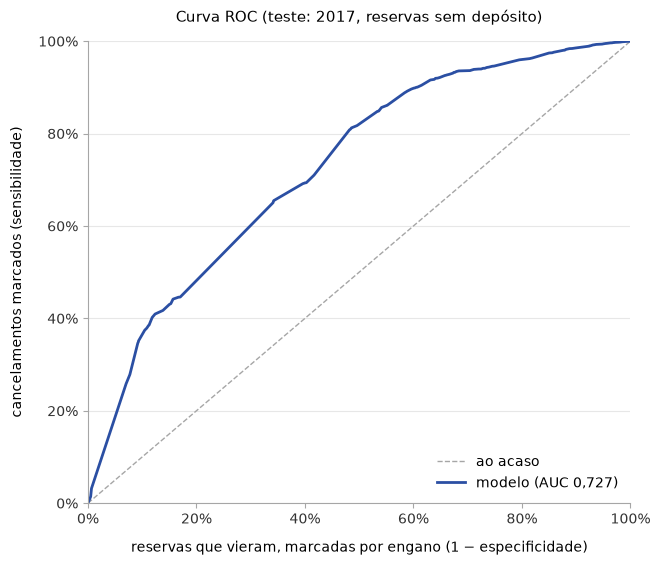

In [21]:
# AUC no treino e no teste, e a curva ROC em 2017
teste = dados[dados['arrival_date_year'] == 2017]
prob_teste = modelo.predict(teste)
auc = pd.Series({'treino': roc_auc_score(treino['is_canceled'], prob_treino),
                 'teste (2017)': roc_auc_score(teste['is_canceled'], prob_teste)}, name='AUC').rename_axis('base')
display(auc.to_frame().round(4))

from matplotlib.ticker import PercentFormatter
fpr, tpr, _ = roc_curve(teste['is_canceled'], prob_teste)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], color=CORES['referencia'], linestyle='--', linewidth=1, label='ao acaso')
ax.plot(fpr, tpr, color=CORES['principal'], linewidth=2, label=f"modelo (AUC {auc['teste (2017)']:.3f})".replace('.', ','))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('reservas que vieram, marcadas por engano (1 − especificidade)')
ax.set_ylabel('cancelamentos marcados (sensibilidade)')
ax.set_title('Curva ROC (teste: 2017, reservas sem depósito)')
ax.legend(frameon=False, loc='lower right')
plt.show()

**Leitura.**

- **AUC de 0,738 no treino e 0,727 em 2017.** A ordenação quase não perde força no ano novo.
- **A curva ROC sobe rápido no começo:** as reservas de maior probabilidade concentram os cancelamentos.

#### Cancelamentos encontrados em 2017

O modelo contra as regras simples, ligando para a mesma parcela das reservas de 2017.

In [22]:
# curva de ganho no teste: modelo × regras simples
p_teste, marca_teste = pontuacoes(teste)
print(f'A regra de 30 dias marca {marca_teste:.1%} das reservas de 2017.')
curva_ganho(teste['is_canceled'], p_teste, fracoes + [marca_teste]).round(4)

A regra de 30 dias marca 44.3% das reservas de 2017.


pct_contatadas,modelo,regra 30 dias ao acaso,regra 30 dias ordenada,regra 90 dias ao acaso
0.0500,0.1012,0.0747,0.0994,0.0794
0.1000,0.1991,0.1494,0.1804,0.1589
0.2000,0.3861,0.2987,0.3309,0.3178
0.3000,0.4933,0.4481,0.4699,0.4629
0.4000,0.6057,0.5975,0.6041,0.5397
0.5000,0.6988,0.6962,0.6962,0.6164
0.4428,0.6555,0.6615,0.6615,0.5725


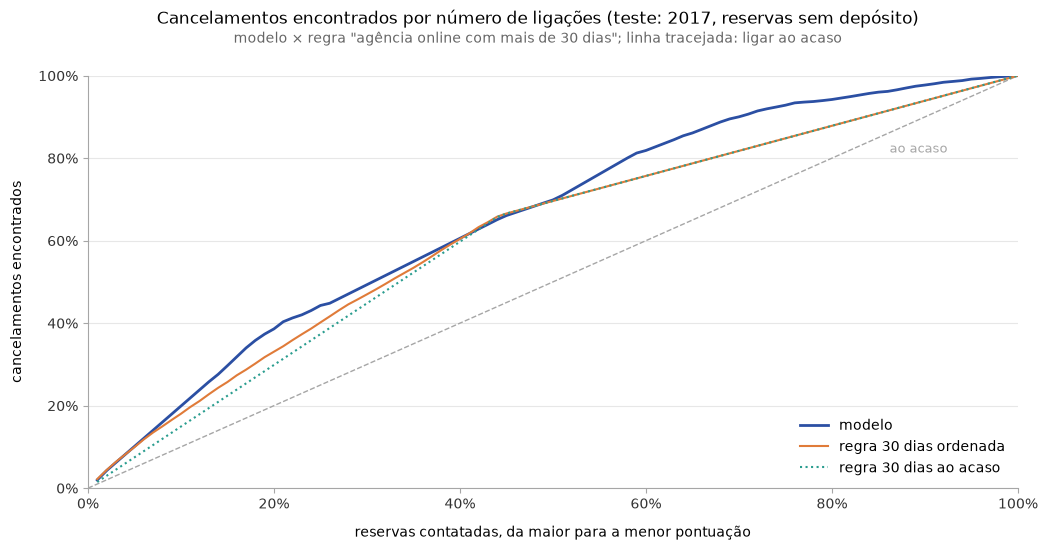

In [23]:
# o mesmo, em gráfico (modelo e regra de 30 dias)
curva = curva_ganho(teste['is_canceled'], {k: p_teste[k] for k in ('modelo', 'regra 30 dias ordenada', 'regra 30 dias ao acaso')},
                    np.linspace(0.01, 1, 100))
grafico_ganho(curva, titulo='Cancelamentos encontrados por número de ligações (teste: 2017, reservas sem depósito)',
              subtitulo='modelo × regra "agência online com mais de 30 dias"; linha tracejada: ligar ao acaso',
              estilos={'modelo': {'color': CORES['principal'], 'linewidth': 2},
                       'regra 30 dias ordenada': {'color': CORES['secundaria']},
                       'regra 30 dias ao acaso': {'color': CORES['terciaria'], 'linestyle': ':'}})
plt.show()

**Leitura.**

- **Em 2017, o modelo encontra mais cancelamentos que as regras quando o hotel liga para 10% a 30% das reservas:** 19,9% contra 18,0% da regra de 30 dias ordenada com 10% das ligações; 38,6% contra 33,1% com 20%; 49,3% contra 47,0% com 30%. A regra de 90 dias encontra 15,9%, 31,8% e 46,3%.
- **A partir de 40%, o modelo e a regra de 30 dias empatam:** 60,6% contra 60,4% com 40%, e 65,6% contra 66,2% nos 44,3% que a regra marca.
- **Por que a régua ficou mais forte em 2017:** a agência online cresceu (04, seção 4), e as regras são feitas sobre ela. A regra de 30 dias passa a marcar 44,3% das reservas, contra 31,1% no treino.

#### Calibração: total e por grupo de risco

A probabilidade média prevista contra a taxa real em 2017, no total e nos grupos de risco (quantis da probabilidade; reservas empatadas ficam no mesmo grupo). O Hosmer-Lemeshow usa os graus de liberdade de uma base nova (o número de grupos).

In [24]:
# calibração no teste: total e por grupo de risco
print(f"Prevista: {prob_teste.mean():.1%} | real: {teste['is_canceled'].mean():.1%}")
print('Hosmer-Lemeshow:', {k: round(v, 4) for k, v in hosmer_lemeshow(teste['is_canceled'], prob_teste, fora_da_amostra=True).items()})
calibracao(teste['is_canceled'], prob_teste, grupos_de_risco(prob_teste)).rename_axis('grupo_de_risco').round(4)

Prevista: 29.2% | real: 31.9%
Hosmer-Lemeshow: {'estatistica': 499.2502, 'gl': 9, 'p_valor': 0.0}


grupo_de_risco,reservas,prob_media,taxa_real,dif_pp
1,3782,0.0442,0.0735,2.9310
2,3548,0.0813,0.1133,3.2031
3,3595,0.1561,0.1324,-2.3655
4,3675,0.2261,0.2615,3.5425
5,3750,0.2626,0.3821,11.9564
6,8623,0.2972,0.3325,3.5263
7,2127,0.3448,0.3310,-1.3824
8,6724,0.6148,0.6090,-0.5784
9,532,0.6752,0.6955,2.0292


**Leitura.**

- **O modelo prevê 29,2% de cancelamento em 2017; a taxa real é 31,9%.** Essa diferença é só parte da alta que as variáveis não explicam: de janeiro a agosto de 2016, o modelo já prevê acima da taxa real (seção 9).
- **Os grupos de maior risco estão bem calibrados:** 61,5% previstos contra 60,9% reais no grupo 8, e 67,5% contra 69,6% no grupo 9. O maior erro é no grupo 5: 26,3% previstos contra 38,2% reais.
- **O Hosmer-Lemeshow rejeita a calibração** (p-valor abaixo de 0,0001), como já acontecia no treino.
- **Para ordenar quem ligar, a calibração importa pouco. Para estimar quantos cancelamentos esperar (overbooking),** as probabilidades precisam de ajuste ao ano e ao mês: o modelo não tem a época do ano.

#### Calibração por segmento e por pedido especial

Os dois pontos que o `04_qualidade_teste` apontou: o perfil de 2017 tem mais agência online e mais pedidos especiais.

In [25]:
# calibração no teste por segmento e por pedido especial
pd.concat({'segmento': calibracao(teste['is_canceled'], prob_teste, teste['segmento3']),
           'pedido especial': calibracao(teste['is_canceled'], prob_teste, teste['pedido_especial'])},
          names=['variavel', 'nivel']).round(4)

variavel,nivel,reservas,prob_media,taxa_real,dif_pp
segmento,agência online,22558,0.3653,0.4092,4.3918
segmento,demais,10743,0.1463,0.1609,1.4601
segmento,grupos,3055,0.2648,0.2049,-5.9896
pedido especial,fez pedido,19239,0.2042,0.2644,6.0123
pedido especial,nenhum,17117,0.3910,0.3797,-1.1224


**Leitura.**

- **A diferença se concentra em dois grupos:** a agência online (36,5% previstos, 40,9% reais: +4,4 pontos) e quem fez pedido especial (20,4% contra 26,4%: +6,0 pontos).
- **Os grupos cancelam menos que o previsto** (26,5% contra 20,5%: −6,0 pontos).
- **O pedido especial continua separando bem** (26,4% contra 38,0% sem pedido), mas a diferença encolhe em 2017. É a variável cuja parcela mais cresceu no ano (04, seção 4).

## 9. A alta de 2017

O cancelamento sobe em 2017. A probabilidade média prevista em cada período mede a parte da alta que vem das **variáveis do modelo** (mais reservas com perfil de risco); o resto é a parte **não explicada pelas variáveis do modelo**. Ela inclui o mesmo perfil cancelando mais e também mudanças em variáveis que ficaram fora do modelo, como a diária e a época do ano. A comparação usa janeiro a agosto nos dois anos.

#### Explicado e não explicado pelas variáveis

In [26]:
# taxa real e prevista: janeiro a agosto de 2016 × 2017
jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
mesmos_meses_2016 = treino[(treino['arrival_date_year'] == 2016) & base.loc[treino.index, 'arrival_date_month'].isin(jan_a_ago)]
periodos = pd.DataFrame({
    'taxa_real': [mesmos_meses_2016['is_canceled'].mean(), teste['is_canceled'].mean()],
    'prob_media_prevista': [modelo.predict(mesmos_meses_2016).mean(), prob_teste.mean()],
}, index=pd.Index(['2016 (jan–ago)', '2017 (jan–ago)'], name='periodo'))
alta = periodos['taxa_real'].diff().iloc[-1] * 100
explicada = periodos['prob_media_prevista'].diff().iloc[-1] * 100
print(f'Alta: {alta:.1f} pontos | explicada pelas variáveis do modelo: {explicada:.1f} | não explicada: {alta - explicada:.1f}')
periodos.round(4)

Alta: 5.5 pontos | explicada pelas variáveis do modelo: 1.3 | não explicada: 4.2


periodo,taxa_real,prob_media_prevista
2016 (jan–ago),0.2636,0.2796
2017 (jan–ago),0.3187,0.2922


**Leitura.**

- **De janeiro a agosto, o cancelamento sobe 5,5 pontos:** de 26,4% em 2016 para 31,9% em 2017.
- **1,3 ponto é explicado pelas variáveis do modelo:** a probabilidade média prevista sobe de 28,0% para 29,2%, porque 2017 tem mais reservas com perfil de risco, como mais agência online e mais antecedência longa (04, seção 4).
- **4,2 pontos não são explicados pelas variáveis do modelo.** Essa parte inclui o mesmo perfil cancelando mais e mudanças em variáveis que ficaram fora do modelo, como a diária, cuja mediana sobe de 95 € para 108 € (04, seção 4), e a época do ano. Em 2016, o próprio modelo já prevê 1,6 ponto acima da taxa real de janeiro a agosto (28,0% contra 26,4%).
- **Para a apresentação:** "a maior parte da alta de 2017 não vem das características que o modelo usa: reservas parecidas nessas características passaram a cancelar mais".

## 10. Ponto de corte

Até onde vale ligar? O corte sai do treino; 2017 só confere. São dois passos.

1. **Escolher o corte na fila.** Imagine as reservas numa fila, da mais arriscada (maior probabilidade) para a menos arriscada, dividida em blocos de 5%. O corte é o **primeiro bloco em que a taxa fica abaixo da média do treino**: ali, a ligação seguinte encontra menos cancelamentos que uma reserva escolhida ao acaso.
2. **Traduzir o corte em probabilidade.** O hotel não vê a fila, só a probabilidade de cada reserva nova. Por isso o corte vira um limiar: a probabilidade da reserva que está no ponto de corte da fila. Se esse ponto cai num grupo de reservas com a mesma probabilidade, o limiar não consegue separá-las, e o corte fica antes do grupo.

O critério não usa custo: mostra até onde a ligação seguinte ainda encontra mais que a média, não até onde dá lucro.

#### Passo 1: a taxa de cada bloco da fila (treino)

In [27]:
# a fila do treino em blocos de 5%: taxa de cada bloco, ponto de corte e limiar de probabilidade
media_treino = treino['is_canceled'].mean()
blocos = taxa_por_bloco(treino['is_canceled'], prob_treino.round(10))
fim_corte = blocos.index[blocos['taxa_bloco'] < media_treino][0][0]
limiar = prob_treino.quantile(1 - fim_corte)
empatadas = prob_treino.round(10) == round(limiar, 10)
liga_treino = prob_treino.round(10) > round(limiar, 10)
print(f'Primeiro bloco abaixo da média ({media_treino:.1%}): começa em {fim_corte:.0%} da fila')
print(f'Probabilidade nesse ponto: {limiar:.1%}, com {empatadas.sum()} reservas empatadas nesse valor, '
      f"que ocupam de {liga_treino.mean():.1%} a {(liga_treino | empatadas).mean():.1%} da fila "
      f"e cancelam {treino.loc[empatadas, 'is_canceled'].mean():.1%}")
perfil_empatadas = treino.loc[empatadas, finais].drop_duplicates()
print(f'Perfis entre as empatadas: {len(perfil_empatadas)} ('
      + ', '.join(f'{NOMES_VARIAVEIS[v]}: {perfil_empatadas[v].iloc[0]}' for v in finais) + ')')
print(f'Corte: ligar para as reservas com probabilidade acima de {limiar:.1%} ({liga_treino.mean():.1%} do treino)')

def pct(v):
    return f'{v:.1%}'.replace('.', ',')

def prob_na_posicao(posicao):
    # a probabilidade da reserva que está nessa posição da fila (0 = a mais arriscada)
    return prob_treino.quantile(1 - posicao)

(blocos.reset_index().head(10)
 .assign(posicao_na_fila=lambda t: [f'{a:.0%} a {b:.0%}' for a, b in zip(t['de'], t['ate'])],
         probabilidade_no_inicio_do_bloco=lambda t: t['de'].map(prob_na_posicao).map(pct),
         cancelam_no_bloco=lambda t: t['taxa_bloco'].map(pct),
         cancelamentos_encontrados_ate_aqui=lambda t: t['cancel_acum'].map(pct))
 [['posicao_na_fila', 'probabilidade_no_inicio_do_bloco', 'cancelam_no_bloco', 'cancelamentos_encontrados_ate_aqui']])

Primeiro bloco abaixo da média (26.8%): começa em 25% da fila
Probabilidade nesse ponto: 30.2%, com 8312 reservas empatadas nesse valor, que ocupam de 23.1% a 35.4% da fila e cancelam 24.4%
Perfis entre as empatadas: 1 (antecedência: mais de 25, pedido especial: fez pedido, segmento (3 níveis): agência online, agência online até 8 dias: não, paga por empresa: sem empresa, hotel: urbano, já veio: nunca veio, sozinho: não, 2 ou mais crianças: não)
Corte: ligar para as reservas com probabilidade acima de 30.2% (23.1% do treino)


posicao_na_fila,probabilidade_no_inicio_do_bloco,cancelam_no_bloco,cancelamentos_encontrados_ate_aqui
0% a 5%,"69,5%","67,6%","12,6%"
5% a 10%,"64,2%","64,6%","24,7%"
10% a 15%,"59,7%","57,0%","35,4%"
15% a 20%,"39,2%","43,3%","43,5%"
20% a 25%,"34,7%","29,9%","49,0%"
25% a 30%,"30,2%","24,4%","53,6%"
30% a 35%,"30,2%","24,4%","58,1%"
35% a 40%,"30,2%","26,7%","63,1%"
40% a 45%,"28,1%","25,7%","67,9%"
45% a 50%,"26,3%","33,4%","74,2%"


**Leitura.**

- **Os quatro primeiros blocos (0% a 20% da fila) cancelam de 43,3% a 67,6%** e concentram 43,5% dos cancelamentos.
- **O bloco de 20% a 25% ainda fica acima da média (29,9%); o de 25% a 30% fica abaixo (24,4%).** O corte cai em 25% da fila.
- **Nesse ponto, a probabilidade é 30,2%, mas ali há um grupo de 8.312 reservas empatadas,** que ocupam de 23,1% a 35,4% da fila e cancelam 24,4%. Por isso a tabela repete 30,2% de 25% a 40% da fila, e os blocos de 25% a 30% e de 30% a 35% têm a mesma taxa: são o mesmo grupo.
- **As empatadas são um perfil só:** agência online, mais de 25 dias, com pedido especial, hotel urbano e sem os outros fatores. É o perfil-exemplo da seção 6 com pedido especial.
- **O limiar não separa as empatadas, e o corte fica antes delas:** ligar para as reservas com probabilidade acima de 30,2%, as 23,1% mais arriscadas do treino.
- **Depois do corte, os blocos ficam perto da média** (de 24,4% a 26,7% entre 25% e 45% da fila), **mas o de 45% a 50% cancela 33,4%.** O passo 2 mostra em que faixa de probabilidade essas reservas estão.

#### Passo 2: o corte em probabilidade (treino)

As mesmas reservas do treino, agora agrupadas por faixa de probabilidade prevista, da mais alta para a mais baixa. As empatadas em 30,2% formam uma faixa própria. A largura de cada barra é a parcela das reservas na faixa; assim, o eixo x continua sendo a fila, mas marcado pela probabilidade.

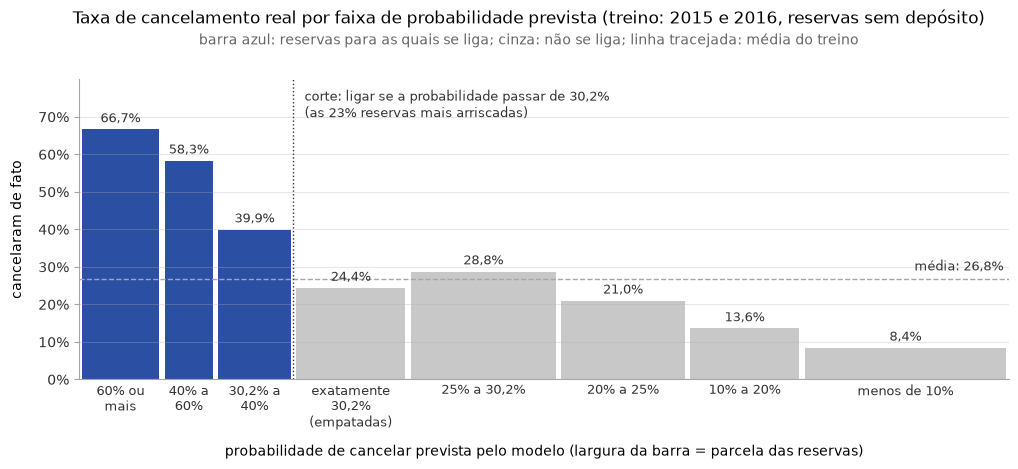

In [28]:
# taxa real por faixa de probabilidade prevista; as empatadas no limiar formam uma faixa própria (treino)
faixas = taxa_por_faixa(treino['is_canceled'], prob_treino, [0.1, 0.2, 0.25, 0.4, 0.6], limiar)
grafico_faixas(faixas, media_treino,
               rotulo_corte=f'corte: ligar se a probabilidade passar de {pct(limiar)}\n'
                            f'(as {liga_treino.mean():.0%} reservas mais arriscadas)',
               titulo='Taxa de cancelamento real por faixa de probabilidade prevista (treino: 2015 e 2016, reservas sem depósito)',
               subtitulo='barra azul: reservas para as quais se liga; cinza: não se liga; linha tracejada: média do treino')
plt.show()

**Leitura.**

- **O 30,2% é a fronteira entre o azul e o cinza.** As três faixas acima dele cancelam de 39,9% a 66,7%, todas bem acima da média (26,8%).
- **"Probabilidade acima de 30,2%" e "as 23% mais arriscadas" são o mesmo grupo de reservas:** a fila serve para escolher o corte; a probabilidade, para aplicá-lo a uma reserva nova.
- **As empatadas em 30,2% cancelam 24,4%, abaixo da média:** são o primeiro grupo da fila abaixo da média, e o corte fica antes delas.
- **A faixa logo abaixo, de 25% a 30,2%, cancela 28,8%:** um pouco acima da média e acima das empatadas. O bloco de 45% a 50% da fila (passo 1), que começa com probabilidade de 26,3%, está nessa faixa. Daí para baixo, as faixas caem: 21,0%, 13,6% e 8,4%.

In [29]:
# probabilidade média prevista × taxa real em cada faixa (treino)
(faixas[['reservas', 'parcela', 'prob_media', 'taxa']]
 .rename(columns={'parcela': 'parcela_das_reservas', 'prob_media': 'prob_media_prevista', 'taxa': 'cancelam_de_fato'})
 .round(4))

faixa,reservas,parcela_das_reservas,prob_media_prevista,cancelam_de_fato
60% ou mais,6024,0.0893,0.6413,0.6665
40% a 60%,3885,0.0576,0.5600,0.5830
"30,2% a 40%",5649,0.0837,0.3643,0.3994
"exatamente 30,2%",8312,0.1232,0.3023,0.2439
"25% a 30,2%",10923,0.1619,0.2725,0.2876
20% a 25%,9336,0.1384,0.2327,0.2097
10% a 20%,8311,0.1232,0.1604,0.1358
menos de 10%,15015,0.2226,0.0642,0.0842


**Leitura.**

- **O modelo superestima as empatadas:** prevê 30,2%, e elas cancelam 24,4%. Na faixa de 25% a 30,2%, prevê em média 27,3%, e elas cancelam 28,8%.
- **Por isso a fila não cai de forma contínua nesse trecho:** o perfil empatado fica à frente na fila, e a faixa logo abaixo cancela mais que ele.
- **O critério para no primeiro grupo abaixo da média** e não chega à faixa de 25% a 30,2%. **Se a equipe puder ligar para mais reservas, essa faixa é a próxima candidata:** 16,2% do treino, com 28,8% de cancelamento, um pouco acima da média.

#### Decisão: para quantas reservas ligar (2017)

Cada linha é um volume de ligações possível. O limiar de probabilidade de cada volume sai do treino (a probabilidade nessa posição da fila do treino) e é aplicado às reservas de 2017. **Precisão:** das reservas ligadas, quantas cancelam. **Recall:** dos cancelamentos de 2017, quantos estão entre as ligadas. A última coluna é o recall da regra "agência online com mais de 30 dias", ordenada pela antecedência, ligando para o mesmo número de reservas.

In [30]:
# volumes de ligação: o limiar sai do treino; o resultado é medido em 2017
def resultado(limiar_volume):
    liga = prob_teste.round(10) > round(limiar_volume, 10)
    return {'ligar se a probabilidade passar de': limiar_volume,
            'reservas ligadas': liga.mean(),
            'das ligadas, cancelam (precisão)': teste.loc[liga, 'is_canceled'].mean(),
            'cancelamentos encontrados (recall)': teste.loc[liga, 'is_canceled'].sum() / teste['is_canceled'].sum(),
            'recall da regra de 30 dias': curva_ganho(teste['is_canceled'], {'regra': p_teste['regra 30 dias ordenada']},
                                                      [liga.mean()])['regra'].iloc[0]}

volumes = {'10% da fila do treino': prob_treino.quantile(0.90),
           '20% da fila do treino': prob_treino.quantile(0.80),
           f'o corte ({fim_corte:.0%} da fila)': limiar,
           '40% da fila do treino': prob_treino.quantile(0.60)}
decisao = pd.DataFrame({nome: resultado(l) for nome, l in volumes.items()}).T
decisao.loc['ligar ao acaso'] = [np.nan, np.nan, teste['is_canceled'].mean(), np.nan, np.nan]
decisao.rename_axis('volume de ligações').apply(lambda coluna: coluna.map(lambda v: '' if pd.isna(v) else pct(v)))

volume de ligações,ligar se a probabilidade passar de,reservas ligadas,"das ligadas, cancelam (precisão)",cancelamentos encontrados (recall),recall da regra de 30 dias
10% da fila do treino,"59,7%","14,1%","62,8%","27,8%","24,5%"
20% da fila do treino,"34,7%","22,7%","58,5%","41,7%","36,9%"
o corte (25% da fila),"30,2%","25,8%","55,1%","44,6%","41,3%"
40% da fila do treino,"28,1%","44,2%","47,2%","65,5%","66,1%"
ligar ao acaso,,,"31,9%",,


**Leitura.**

- **No corte, o hotel liga para 25,8% das reservas de 2017:** 55,1% delas cancelam, e elas concentram 44,6% dos cancelamentos. A regra de 30 dias, com as mesmas ligações, encontra 41,3%.
- **Com menos ligações, a precisão sobe e o recall cai:** com o limiar de 59,7%, o hotel liga para 14,1% das reservas, 62,8% delas cancelam, e o recall é 27,8%.
- **Com mais ligações, o recall sobe e a precisão cai:** com o limiar de 28,1%, liga para 44,2%, encontra 65,5% dos cancelamentos, mas só 47,2% das ligadas cancelam; nesse volume, a regra de 30 dias encontra um pouco mais (66,1%).
- **Em todos os volumes, a precisão fica acima de ligar ao acaso (31,9%),** e até o corte o modelo encontra mais cancelamentos que a regra.
- **Os volumes de 2017 não são os do treino** (14,1% em vez de 10%), porque o limiar vem do treino, o perfil de 2017 é outro (04, seção 4) e muitas reservas têm a mesma probabilidade.
- **Para a apresentação:** "ligando para 1 em cada 4 reservas, as com mais de 30% de chance de cancelar, o hotel encontra 45% dos cancelamentos, e mais da metade das ligações acerta".

#### Matriz de confusão no corte (2017)

As reservas de 2017 divididas pelo corte (ligar ou não) e pelo desfecho (cancelou ou veio). **Precisão:** das reservas ligadas, quantas cancelam. **Recall** (sensibilidade): dos cancelamentos, quantos estão entre as ligadas. **Especificidade:** das reservas que vieram, quantas ficaram fora das ligações.

In [31]:
# matriz de confusão e medidas no corte (2017)
liga_teste = prob_teste.round(10) > round(limiar, 10)
matriz = pd.crosstab(liga_teste.map({True: 'ligar', False: 'não ligar'}), teste['is_canceled'].map({1: 'cancelou', 0: 'veio'}))
matriz = matriz.rename_axis('decisao').rename_axis(None, axis=1)[['cancelou', 'veio']]
display(matriz)
vp, fp = matriz.loc['ligar', 'cancelou'], matriz.loc['ligar', 'veio']
fn, vn = matriz.loc['não ligar', 'cancelou'], matriz.loc['não ligar', 'veio']
pd.Series({'precisao': vp / (vp + fp), 'recall': vp / (vp + fn), 'especificidade': vn / (vn + fp),
           'acuracia': (vp + vn) / matriz.to_numpy().sum(), 'taxa_ao_acaso': teste['is_canceled'].mean()},
          name='valor').rename_axis('medida').to_frame().round(4)

decisao,cancelou,veio
ligar,5169,4214
não ligar,6417,20556


medida,valor
precisao,0.5509
recall,0.4461
especificidade,0.8299
acuracia,0.7076
taxa_ao_acaso,0.3187


**Leitura.**

- **Precisão de 55,1%:** das 9.383 reservas ligadas, 5.169 cancelam. Ligando ao acaso, seriam 31,9%.
- **Recall de 44,6%:** 5.169 cancelamentos encontrados; 6.417 ficam entre as reservas não ligadas.
- **Especificidade de 83,0%:** das reservas que vieram, 20.556 ficam fora das ligações, e 4.214 recebem uma ligação sem precisar.
- **A acurácia (70,8%) diz pouco aqui,** porque a maioria das reservas vem: o que importa é quantos cancelamentos as ligações encontram e quantas ligações acertam.

## 11. Sensibilidade: sem as linhas idênticas

As 31.994 linhas idênticas ficaram na base (notebook 01, seção 4.2): são, provavelmente, vários quartos de uma mesma reserva. Aqui o modelo escolhido é ajustado de novo com uma linha de cada grupo idêntico. Os dois modelos são comparados nos coeficientes e no mesmo teste: 2017 sem as linhas idênticas.

#### Coeficientes com e sem as linhas idênticas

In [32]:
# o mesmo modelo, com uma linha de cada grupo de linhas idênticas (treino)
unicas = hotel.drop_duplicates().index
treino_unico = treino[treino.index.isin(unicas)]
modelo_unico = ajustar_logistica(formula_final, treino_unico)
print('Treino sem as linhas idênticas:', len(treino_unico), f"| cancelamento {treino_unico['is_canceled'].mean():.1%}")
pd.DataFrame({'razao_chances': np.exp(modelo.params), 'razao_chances_sem_identicas': np.exp(modelo_unico.params)}
             ).drop(index='Intercept').rename_axis('coeficiente').round(4)

Treino sem as linhas idênticas: 54320 | cancelamento 24.3%


coeficiente,razao_chances,razao_chances_sem_identicas
antecedencia[T.0],0.2652,0.2713
antecedencia[T.1–8],0.5831,0.6200
antecedencia[T.9–25],0.6461,0.6856
pedido_especial[T.fez pedido],0.2412,0.2712
segmento3[T.grupos],0.3588,0.1824
segmento3[T.demais],0.2179,0.1886
online_ate8[T.sim],0.2779,0.2652
paga_empresa[T.paga por empresa],0.6890,0.8779
hotel[T.resort],0.8257,0.9029
ja_veio[T.já veio],0.5444,0.4810


**Leitura.**

- **Sem as linhas idênticas, o treino tem 54.320 reservas e 24,3% de cancelamento.**
- **Todas as razões de chances mantêm o lado do 1:** os fatores que reduzem o cancelamento continuam reduzindo, e 2 ou mais crianças continua aumentando.
- **Três mudam de tamanho:** grupos (0,36 para 0,18), paga por empresa (0,69 para 0,88) e sozinho (0,84 para 0,97). As linhas idênticas são, em boa parte, blocos de grupos e de empresas (01, seção 4.2).

#### Os dois modelos no mesmo teste

In [33]:
# os dois modelos em 2017 sem as linhas idênticas: AUC e cancelamentos encontrados
teste_unico = teste[teste.index.isin(unicas)]
y_unico = teste_unico['is_canceled']
pd.DataFrame({nome: {'AUC': roc_auc_score(y_unico, m.predict(teste_unico)),
                     **{f'encontrados_{f:.0%}': parcela_capturada(y_unico, m.predict(teste_unico).round(10), f) for f in (0.10, 0.20, 0.30)}}
              for nome, m in [('modelo', modelo), ('modelo sem as linhas idênticas', modelo_unico)]}
             ).T.rename_axis('modelo').round(4)

modelo,AUC,encontrados_10%,encontrados_20%,encontrados_30%
modelo,0.7257,0.1990,0.3898,0.4974
modelo sem as linhas idênticas,0.7361,0.1991,0.3898,0.5068


**Leitura.**

- **No mesmo teste, os dois modelos ordenam quase igual:** AUC de 0,726 e 0,736; com 10%, 20% e 30% das ligações, encontram 19,9% e 19,9%, 39,0% e 39,0%, 49,7% e 50,7% dos cancelamentos.
- **A recomendação não depende das linhas idênticas.**

## 12. Dicionário de dados, versão final

A terceira versão (02, seção 4), com as decisões do 03 e deste notebook. As razões de chances são as do modelo escolhido.

| Variável original | No modelo | Forma | Razão de chances | Por quê |
| :--- | :--- | :--- | :--- | :--- |
| `lead_time` | **entra** | antecedência: 0 / 1–8 / 9–25 / mais de 25 dias (ref.) | 0,27 / 0,58 / 0,65 (fora da agência online) | Mais antecedência, mais cancelamento (02, 3.1) |
| `total_of_special_requests` | **entra** | pedido especial: fez pedido / nenhum (ref.) | 0,24 | O score é calculado alguns dias depois da reserva |
| `market_segment` | **entra** | segmento: agência online (ref.) / grupos / demais | 0,36 / 0,22 (com mais de 8 dias) | Com as outras variáveis, os 3 níveis mantêm o sinal nos dois anos (seção 4) |
| `market_segment` × `lead_time` | **entra** | agência online com até 8 dias: sim / não (ref.) | 0,28 | Na agência online, a reserva de última hora cancela bem menos (seção 4) |
| `company` | **entra** | paga por empresa: sim / não (ref.) | 0,69 | 02, 3.17 |
| `hotel` | **entra** | hotel: urbano (ref.) / resort | 0,83 | 02, 3.10 |
| `previous_bookings_not_canceled` | **entra** | já veio: sim / nunca veio (ref.) | 0,54 | 02, 3.9 |
| `adults` | **entra** | sozinho: sim / não (ref.) | 0,84 | 02, 3.4 |
| `children` | **entra** | 2 ou mais crianças: sim / não (ref.) | 1,27 | 02, 3.5 |
| `arrival_date_month` | sai | | | O efeito de julho e agosto some em 2016 com as outras variáveis no modelo (seção 5) |
| `adr` | sai | | | Inverte o sinal entre 2015 e 2016 (seção 5) |
| `stays_*_nights` | sai | | | Não reduz o BIC no stepwise final (seção 5) |
| `babies` | sai | | | "Com bebê" não reduz o BIC com o pedido especial no modelo (seção 2) |
| `agent` | sai | | | No modelo, sem agência cancelaria mais; na comparação direta, cancela 14,5% contra 28,8% (seção 5) |
| `distribution_channel` | sai | | | No modelo, "demais" cancelaria mais; na comparação direta, cancela 15,4% contra 29,6% (seção 5) |
| As demais | saem | | | Como na terceira versão (02, seção 4) e na segunda (01, seção 6) |
| `is_canceled` | resposta | 1 = cancelada, 0 = veio | | 26,8% no treino; 31,9% em 2017 |

## 13. Conclusão: a história

A história dos notebooks 01 a 05, no roteiro da apresentação. Os números saem das seções citadas.

**1. O problema e a decisão**

- Entre as reservas sem garantia de pagamento, 28,4% são canceladas (01, seção 5.2). Em 2017, 31,9% (seção 9).
- A decisão: em quais reservas ligar para confirmar ou pedir depósito, sem gastar a equipe com quem vai vir de qualquer jeito.

**2. Como o modelo funciona**

- Alguns dias depois da reserva, o modelo dá a cada uma a probabilidade de cancelar, a partir de 9 características que o hotel já tem: antecedência, pedido especial, segmento, agência online com reserva de última hora, empresa que paga, hotel, cliente que já veio, viagem sozinho e 2 ou mais crianças.
- Exemplo (seção 6): uma reserva da agência online feita com 60 dias, sem pedido especial, tem 64,2% de chance de cancelar; com um pedido especial, 30,2%.

**3. O que os dados mostram**

- **Os fatores mais fortes** (seção 6): o pedido especial, o segmento e a antecedência. A agência online com antecedência longa concentra o risco; a reserva de última hora, mesmo na agência online, cancela pouco.
- **Contra uma regra simples** (seção 8): ligando para 20% das reservas de 2017, o modelo encontra 38,6% dos cancelamentos; a regra "agência online com mais de 30 dias", ordenada pela antecedência, encontra 33,1%. A partir de 40% das ligações, os dois empatam.
- **Limitações:**
  - dois hotéis em Portugal, de 2015 a 2017, antes da pandemia; o modelo mostra associação, não causa;
  - em 2017, 4,2 dos 5,5 pontos de alta não são explicados pelas variáveis do modelo (seção 9), e as probabilidades saem baixas para 2017 (seção 8);
  - linhas idênticas (provavelmente vários quartos de uma reserva) deixam os intervalos otimistas, mas não mudam a ordenação (seção 11).

**4. Recomendação e próximos passos**

- **Ligar para as reservas com mais de 30% de chance de cancelar** (seção 10). É o mesmo que ligar para o começo da fila, as reservas mais arriscadas: cerca de 1 em cada 4. Em 2017, são 25,8% das reservas; 55,1% delas cancelam, e elas concentram 44,6% dos cancelamentos. Se a equipe puder ligar para mais reservas, a faixa logo abaixo do corte (de 25% a 30,2% de probabilidade, 16,2% das reservas do treino) ainda cancela 28,8%, um pouco acima da média (seção 10).
- **Próximos passos:**
  - um piloto A/B, para medir se a ligação reduz o cancelamento: o modelo diz quem tem mais risco, não o efeito da ligação;
  - a premissa de custo (quanto custa uma ligação, quanto se recupera), para trocar o critério do corte por lucro;
  - validar em dados novos duas interações que melhoram o ajuste no treino: hotel × pedido especial e agência online × antecedência longa;
  - ajustar as probabilidades ao ano e ao mês antes de usá-las no overbooking.

## Decisões para o grupo

*Seção temporária: cada ponto sai daqui quando o grupo decidir. A comparação completa está em `comparacao_decisoes.md`.*

| # | Decisão | Proposta deste notebook | Evidência | Grupo |
| --- | --- | --- | --- | --- |
| 1 | **Momento do score** | Alguns dias depois da reserva, junto com a ligação de confirmação: o pedido especial entra. Sem ele, o BIC piora 4.367,7 pontos | 6 | Notebook 03: mesma proposta, se o pedido entrar |
| 2 | **Seleção** | Stepwise pelo BIC, com duas regras: o sinal precisa ser o mesmo em 2015 e 2016, e o efeito precisa ter o sentido da comparação direta | 2 e 5 | `TODO.md`: com e sem cada variável, pelo AIC |
| 3 | **Segmento** | 3 níveis: agência online, grupos e demais | 4 | Todos os segmentos |
| 4 | **Interação** | Agência online com até 8 dias de antecedência | 4 | Notebook 03 e `TODO.md`: testar agência online × antecedência |
| 5 | **Temporada e diária** | Saem: invertem o sinal entre 2015 e 2016 com as outras variáveis no modelo | 5 | Três temporadas fixas; diária como número |
| 6 | **Tem agência e canal** | Saem pela regra do sentido: no modelo, cancelariam mais sem agência e fora de agência ou operadora, o contrário da comparação direta. Custo: 45,9 e 33,4 pontos de BIC | 5 | Saem |
| 7 | **Resultado contra a régua** | Em 2017, o modelo encontra mais cancelamentos que a regra "agência online com mais de 30 dias" com 10% a 30% das ligações e empata a partir de 40% | 8 | Notebook 02: régua de 66% dos cancelamentos com 44% das reservas |
| 8 | **Calibração** | Em 2017, prevê 29,2% contra 31,9% reais; no treino, o Hosmer-Lemeshow também rejeita. As probabilidades precisam de ajuste ao ano e ao mês se forem usadas para overbooking | 6 e 8 | `TODO.md`: conferir a calibração |
| 9 | **Ponto de corte** | Ligar para as reservas com probabilidade acima de 30,2%: o primeiro bloco de ligações com taxa abaixo da média do treino. Em 2017, 25,8% das reservas, precisão de 55,1% e recall de 44,6%. Sem premissa de custo | 10 | `TODO.md`: ponto de corte pela premissa de custo |
| 10 | **Alta de 2017** | 1,3 ponto explicado pelas variáveis do modelo e 4,2 não explicados, calculados depois do modelo fechado | 9 | Notebook 03: decomposição antes do modelo |
| 11 | **Interação hotel × pedido especial** | Fica como próximo passo: melhora o ajuste no treino, mas foi encontrada depois da avaliação em 2017 | 6 e 13 | — |